In [1]:
import sys
from pathlib import Path

# Encontra o módulo e disponibiliza seu pacote Python, sem depender da pasta atual.
PASTA_ATUAL = Path.cwd().resolve()
PASTA_PROJETO = next(
    (
        pasta
        for base in (PASTA_ATUAL, *PASTA_ATUAL.parents)
        for pasta in (
            base,
            base / "04_regressao_polinomial",
            base / "regressao_modelos_lineares" / "04_regressao_polinomial",
        )
        if (pasta / "src" / "polinomial" / "config.py").is_file()
    ),
    None,
)
if PASTA_PROJETO is None:
    raise FileNotFoundError("Não foi possível localizar o módulo 04_regressao_polinomial.")
PASTA_SRC = PASTA_PROJETO / "src"
if str(PASTA_SRC) not in sys.path:
    sys.path.insert(0, str(PASTA_SRC))

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    PolynomialFeatures,
    PowerTransformer,
    StandardScaler,
    QuantileTransformer,
)

from polinomial.auxiliares import dataframe_coeficientes
from polinomial.config import DADOS_DIABETES_CATEGORIZADOS
from polinomial.graficos import plot_comparar_metricas_modelos, plot_coeficientes
from polinomial.modelos import RANDOM_STATE
from polinomial.modelos import grid_search_cv_regressor, organiza_resultados, treinar_e_validar_modelo_regressao

sns.set_theme(palette="bright")
print(f"Python do kernel: {sys.executable}")
print(f"Base utilizada: {DADOS_DIABETES_CATEGORIZADOS}")


Python do kernel: /home/paulo-vinicius/miniconda3/envs/machine_learn/bin/python
Base utilizada: /home/paulo-vinicius/Documentos/Ciência de Dados/Machine_Learning/regressao_modelos_lineares/04_regressao_polinomial/dados/diabetes_categorizado.parquet


In [2]:
df = pd.read_parquet(DADOS_DIABETES_CATEGORIZADOS)

df.head()

,idade,sexo,imc,pressao_media,colesterol_total,ldl,hdl,triglicerides,glicose,target,colesterol_hdl_cat
0,59,2,32.099998,101.0,157,93.199997,38.0,4.8598,87,151,4-5
1,48,1,21.600000,87.0,183,103.199997,70.0,3.8918,69,75,2-3
2,72,2,30.500000,93.0,156,93.599998,41.0,4.6728,85,141,4-5
3,24,1,25.299999,84.0,198,131.399994,40.0,4.8903,89,206,4-5
4,50,1,23.000000,101.0,192,125.400002,52.0,4.2905,80,135,4-5


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   idade               442 non-null    int8    
 1   sexo                442 non-null    int8    
 2   imc                 442 non-null    float32 
 3   pressao_media       442 non-null    float32 
 4   colesterol_total    442 non-null    int16   
 5   ldl                 442 non-null    float32 
 6   hdl                 442 non-null    float32 
 7   triglicerides       442 non-null    float32 
 8   glicose             442 non-null    int8    
 9   target              442 non-null    int16   
 10  colesterol_hdl_cat  442 non-null    category
dtypes: category(1), float32(5), int16(2), int8(3)
memory usage: 12.3 KB


In [4]:
X = df.drop(columns="target")
y = df["target"]

In [5]:
colunas_power_transform = ["imc", "ldl", "hdl", "colesterol_total"]

coluna_target = ["target"]

coluna_ordinal_encoder = ["colesterol_hdl_cat"]

coluna_one_hot_encoder = ["sexo"]

colunas_standard_scaler = [
    coluna
    for coluna in df.columns
    if coluna not in colunas_power_transform + coluna_target + coluna_ordinal_encoder + coluna_one_hot_encoder
]

colunas_standard_scaler

['idade', 'pressao_media', 'triglicerides', 'glicose']

In [6]:
categorias_ordinal_encoder = [
    ["2-3", "4-5", "6+"],
]

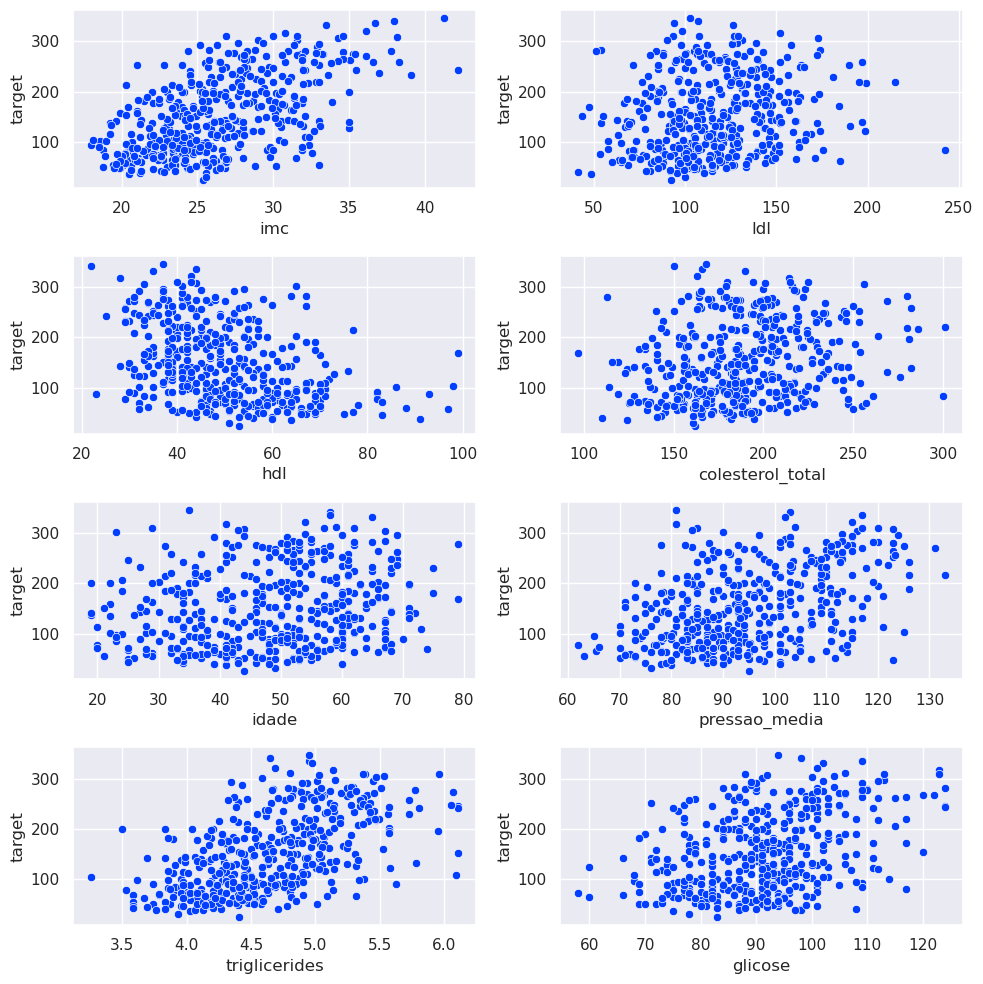

In [7]:
fig, axs = plt.subplots(4, 2, figsize=(10, 10))

for ax, coluna in zip(axs.flatten(), colunas_power_transform + colunas_standard_scaler):
    sns.scatterplot(x=coluna, y="target", data=df, ax=ax)

plt.tight_layout()

plt.show()

In [8]:
pipeline_power = Pipeline([
    ("power_transformer", PowerTransformer(method="box-cox")),
    ("poly", PolynomialFeatures(degree=1, include_bias=False)),
])

pipeline_standard = Pipeline([
    ("standard_scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=1, include_bias=False)),
])

preprocessamento_completo = ColumnTransformer(
    [
        ("power_transform_poly", pipeline_power, colunas_power_transform),
        ("standard_scaler_poly", pipeline_standard, colunas_standard_scaler),
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
    ]
)

target_transformer = QuantileTransformer(n_quantiles=20, output_distribution="normal", random_state=RANDOM_STATE)

In [9]:
elasticnet_regressor = ElasticNet(max_iter=100_000, random_state=RANDOM_STATE)


In [10]:
param_grid = {
    "regressor__reg__alpha": [1E-2, 5E-2, 0.1, 1.0, 5.0, 10],
    "regressor__reg__l1_ratio": [0.1, 0.25, 0.5, 0.75, 0.9],
    "regressor__preprocessor__power_transform_poly__poly__degree": [1, 2, 3],
    "regressor__preprocessor__standard_scaler_poly__poly__degree": [1, 2, 3],
    "transformer": [target_transformer, None]
}

In [11]:
grid_search = grid_search_cv_regressor(
    regressor=elasticnet_regressor,
    param_grid=param_grid,
    preprocessor=preprocessamento_completo,
    target_transformer=target_transformer,
)

# Dois processos para manter o consumo de memória controlado.
grid_search.set_params(n_jobs=2)

# Verifica os nomes das etapas antes de iniciar os 2.700 ajustes.
for configuracao in ParameterGrid(param_grid):
    clone(grid_search.estimator).set_params(**configuracao)
print(f"{len(ParameterGrid(param_grid))} candidatos; {grid_search.cv.n_splits} divisões.")
grid_search


540 candidatos; 5 divisões.


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                                             ColumnTransformer(transformers=[('power_transform_poly',
                                                                                                              Pipeline(steps=[('power_transformer',
                                                                                                                               PowerTransformer(method='box-cox')),
                                                                                                                              ('poly',
                                                                                                                               PolynomialFeatures(degree=1,
                                                                                                                                                  include_bias=False))]),...
                         'regressor__preprocessor__standard_scaler_poly__poly__degree': [1,
                                                                                         2,
                                                                                         3],
                         'regressor__reg__alpha': [0.01, 0.05, 0.1, 1.0, 5.0,
                                                   10],
                         'regressor__reg__l1_ratio': [0.1, 0.25, 0.5, 0.75,
                                                      0.9],
                         'transformer': [QuantileTransformer(n_quantiles=20,
                                                             output_distribution='normal',
                                                             random_state=42),
                                         None]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [12]:
from time import perf_counter

inicio_busca = perf_counter()
grid_search.fit(X, y)

# Confirma que todos os candidatos produziram métricas numéricas válidas.
for metrica in (
    "mean_test_r2",
    "mean_test_neg_mean_absolute_error",
    "mean_test_neg_root_mean_squared_error",
):
    if not np.isfinite(grid_search.cv_results_[metrica]).all():
        raise ValueError(f"A busca gerou valores não finitos em {metrica}.")
print(f"Busca concluída em {perf_counter() - inicio_busca:.1f} segundos.")
print(f"Melhor RMSE de validação: {-grid_search.best_score_:.4f}")

Fitting 5 folds for each of 540 candidates, totalling 2700 fits


Busca concluída em 94.1 segundos.
Melhor RMSE de validação: 54.6073


In [13]:
grid_search.best_params_

{'regressor__preprocessor__power_transform_poly__poly__degree': 1,
 'regressor__preprocessor__standard_scaler_poly__poly__degree': 2,
 'regressor__reg__alpha': 0.05,
 'regressor__reg__l1_ratio': 0.25,
 'transformer': QuantileTransformer(n_quantiles=20, output_distribution='normal',
                     random_state=42)}

In [14]:
grid_search.best_score_

-54.60725628631015

In [15]:
grid_search.best_estimator_

TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('power_transform_poly',
                                                                                       Pipeline(steps=[('power_transformer',
                                                                                                        PowerTransformer(method='box-cox')),
                                                                                                       ('poly',
                                                                                                        PolynomialFeatures(degree=1,
                                                                                                                           include_bias=False))]),
                                                                                       ['imc',
                                                                                        'ldl',
                                                                                        'hdl',
                                                                                        'colesterol_total']),
                                                                                      ('standard_scaler_poly',
                                                                                       Pipeline(steps=[('standard_sc...
                                                                                        'triglicerides',
                                                                                        'glicose']),
                                                                                      ('ordinal_encoder',
                                                                                       OrdinalEncoder(categories=[['2-3',
                                                                                                                   '4-5',
                                                                                                                   '6+']]),
                                                                                       ['colesterol_hdl_cat']),
                                                                                      ('one_hot_encoder',
                                                                                       OneHotEncoder(drop='if_binary'),
                                                                                       ['sexo'])])),
                                                     ('reg',
                                                      ElasticNet(alpha=0.05,
                                                                 l1_ratio=0.25,
                                                                 max_iter=100000,
                                                                 random_state=42))]),
                           transformer=QuantileTransformer(n_quantiles=20,
                                                           output_distribution='normal',
                                                           random_state=42))

In [16]:
print(*grid_search.cv_results_.keys(), sep="\n")

mean_fit_time
std_fit_time
mean_score_time
std_score_time
param_regressor__preprocessor__power_transform_poly__poly__degree
param_regressor__preprocessor__standard_scaler_poly__poly__degree
param_regressor__reg__alpha
param_regressor__reg__l1_ratio
param_transformer
params
split0_test_r2
split1_test_r2
split2_test_r2
split3_test_r2
split4_test_r2
mean_test_r2
std_test_r2
rank_test_r2
split0_test_neg_mean_absolute_error
split1_test_neg_mean_absolute_error
split2_test_neg_mean_absolute_error
split3_test_neg_mean_absolute_error
split4_test_neg_mean_absolute_error
mean_test_neg_mean_absolute_error
std_test_neg_mean_absolute_error
rank_test_neg_mean_absolute_error
split0_test_neg_root_mean_squared_error
split1_test_neg_root_mean_squared_error
split2_test_neg_root_mean_squared_error
split3_test_neg_root_mean_squared_error
split4_test_neg_root_mean_squared_error
mean_test_neg_root_mean_squared_error
std_test_neg_root_mean_squared_error
rank_test_neg_root_mean_squared_error


In [17]:
max(grid_search.cv_results_["mean_test_neg_root_mean_squared_error"])

-54.60725628631015

In [18]:
grid_search.best_estimator_

TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('power_transform_poly',
                                                                                       Pipeline(steps=[('power_transformer',
                                                                                                        PowerTransformer(method='box-cox')),
                                                                                                       ('poly',
                                                                                                        PolynomialFeatures(degree=1,
                                                                                                                           include_bias=False))]),
                                                                                       ['imc',
                                                                                        'ldl',
                                                                                        'hdl',
                                                                                        'colesterol_total']),
                                                                                      ('standard_scaler_poly',
                                                                                       Pipeline(steps=[('standard_sc...
                                                                                        'triglicerides',
                                                                                        'glicose']),
                                                                                      ('ordinal_encoder',
                                                                                       OrdinalEncoder(categories=[['2-3',
                                                                                                                   '4-5',
                                                                                                                   '6+']]),
                                                                                       ['colesterol_hdl_cat']),
                                                                                      ('one_hot_encoder',
                                                                                       OneHotEncoder(drop='if_binary'),
                                                                                       ['sexo'])])),
                                                     ('reg',
                                                      ElasticNet(alpha=0.05,
                                                                 l1_ratio=0.25,
                                                                 max_iter=100000,
                                                                 random_state=42))]),
                           transformer=QuantileTransformer(n_quantiles=20,
                                                           output_distribution='normal',
                                                           random_state=42))

In [19]:
grid_search.best_estimator_.regressor_["preprocessor"]

ColumnTransformer(transformers=[('power_transform_poly',
                                 Pipeline(steps=[('power_transformer',
                                                  PowerTransformer(method='box-cox')),
                                                 ('poly',
                                                  PolynomialFeatures(degree=1,
                                                                     include_bias=False))]),
                                 ['imc', 'ldl', 'hdl', 'colesterol_total']),
                                ('standard_scaler_poly',
                                 Pipeline(steps=[('standard_scaler',
                                                  StandardScaler()),
                                                 ('poly',
                                                  PolynomialFeatures(include_bias=False))]),
                                 ['idade', 'pressao_media', 'triglicerides',
                                  'glicose']),
                                ('ordinal_encoder',
                                 OrdinalEncoder(categories=[['2-3', '4-5',
                                                             '6+']]),
                                 ['colesterol_hdl_cat']),
                                ('one_hot_encoder',
                                 OneHotEncoder(drop='if_binary'), ['sexo'])])

In [20]:
grid_search.best_estimator_.regressor_["reg"]

ElasticNet(alpha=0.05, l1_ratio=0.25, max_iter=100000, random_state=42)

In [21]:
grid_search.best_estimator_.transformer_

QuantileTransformer(n_quantiles=20, output_distribution='normal',
                    random_state=42)

In [22]:
grid_search.best_estimator_.regressor_["reg"].coef_

array([ 0.31290373, -0.00046145, -0.13981468, -0.0333608 ,  0.        ,
        0.13360847,  0.29401948,  0.02768333,  0.05814116,  0.04130101,
        0.00447216,  0.01447626,  0.02364184,  0.        , -0.        ,
       -0.03567403,  0.        ,  0.04892382,  0.00075662, -0.16320086])

In [23]:
grid_search.best_estimator_.regressor_["reg"].intercept_

-0.030120824975806117

In [24]:
grid_search.best_estimator_.regressor_["preprocessor"].get_feature_names_out()

array(['power_transform_poly__imc', 'power_transform_poly__ldl',
       'power_transform_poly__hdl',
       'power_transform_poly__colesterol_total',
       'standard_scaler_poly__idade',
       'standard_scaler_poly__pressao_media',
       'standard_scaler_poly__triglicerides',
       'standard_scaler_poly__glicose', 'standard_scaler_poly__idade^2',
       'standard_scaler_poly__idade pressao_media',
       'standard_scaler_poly__idade triglicerides',
       'standard_scaler_poly__idade glicose',
       'standard_scaler_poly__pressao_media^2',
       'standard_scaler_poly__pressao_media triglicerides',
       'standard_scaler_poly__pressao_media glicose',
       'standard_scaler_poly__triglicerides^2',
       'standard_scaler_poly__triglicerides glicose',
       'standard_scaler_poly__glicose^2',
       'ordinal_encoder__colesterol_hdl_cat', 'one_hot_encoder__sexo_2'],
      dtype=object)

In [25]:
coefs = dataframe_coeficientes(
    grid_search.best_estimator_.regressor_["reg"].coef_,
    grid_search.best_estimator_.regressor_["preprocessor"].get_feature_names_out()
)

coefs

,coeficiente
one_hot_encoder__sexo_2,-0.163201
power_transform_poly__hdl,-0.139815
standard_scaler_poly__triglicerides^2,-0.035674
power_transform_poly__colesterol_total,-0.033361
power_transform_poly__ldl,-0.000461
standard_scaler_poly__idade,0.000000
standard_scaler_poly__triglicerides glicose,0.000000
standard_scaler_poly__pressao_media glicose,-0.000000
standard_scaler_poly__pressao_media triglicerides,0.000000
ordinal_encoder__colesterol_hdl_cat,0.000757


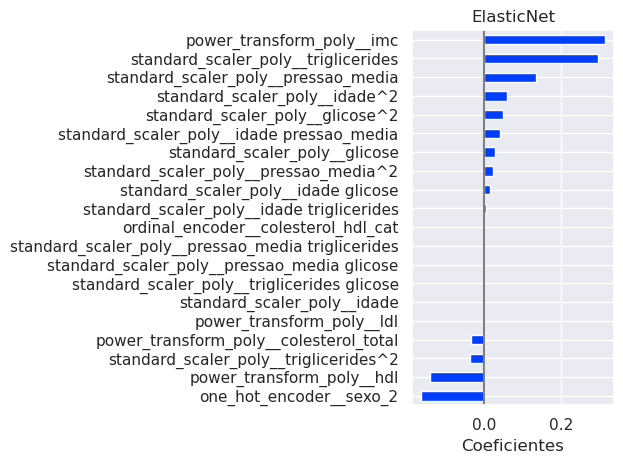

In [26]:
plot_coeficientes(coefs, "ElasticNet")

In [27]:
regressors = {
    "DummyRegressor": {
        "preprocessor": None,
        "regressor": DummyRegressor(strategy="mean"),
        "target_transformer": None,
    },
    
    "LinearRegression_pre_completo": {
        "preprocessor": preprocessamento_completo,
        "regressor": LinearRegression(),
        "target_transformer": None,
    },
    "ElasticNet_grid_search": {
        "preprocessor": grid_search.best_estimator_.regressor_["preprocessor"],
        "regressor": grid_search.best_estimator_.regressor_["reg"],
        "target_transformer": grid_search.best_params_["transformer"],
    },
}

In [28]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_regressao(X, y, **regressor)
    for nome_modelo, regressor in regressors.items()
}

resultados

{'DummyRegressor': {'fit_time': array([0.00102711, 0.00072408, 0.00060153, 0.00057101, 0.00061703]),
  'score_time': array([0.00096083, 0.00102472, 0.00078154, 0.00076509, 0.00112343]),
  'test_r2': array([-0.01196298, -0.02697753, -0.01530397, -0.00021233, -0.04231598]),
  'test_neg_mean_absolute_error': array([-64.00646147, -70.57793551, -59.82954545, -70.05392912,
         -65.42565485]),
  'test_neg_root_mean_squared_error': array([-73.22249284, -80.04318688, -74.33859714, -82.04745226,
         -76.3152967 ])},
 'LinearRegression_pre_completo': {'fit_time': array([0.05241489, 0.05576158, 0.04658246, 0.0538094 , 0.05599236]),
  'score_time': array([0.00424886, 0.00419879, 0.00396156, 0.0041635 , 0.00394511]),
  'test_r2': array([0.44182617, 0.57230565, 0.40822373, 0.571594  , 0.38616274]),
  'test_neg_mean_absolute_error': array([-43.64265398, -41.89732167, -46.45066694, -42.77940995,
         -47.8440119 ]),
  'test_neg_root_mean_squared_error': array([-54.38096757, -51.65479688, 

In [29]:
df_resultados = organiza_resultados(resultados)

df_resultados

,fit_time,score_time,test_r2,test_neg_mean_absolute_error,test_neg_root_mean_squared_error,model,time_seconds,MAE,RMSE
0,0.001027,0.000961,-0.011963,-64.006461,-73.222493,DummyRegressor,0.001988,64.006461,73.222493
1,0.000724,0.001025,-0.026978,-70.577936,-80.043187,DummyRegressor,0.001749,70.577936,80.043187
2,0.000602,0.000782,-0.015304,-59.829545,-74.338597,DummyRegressor,0.001383,59.829545,74.338597
3,0.000571,0.000765,-0.000212,-70.053929,-82.047452,DummyRegressor,0.001336,70.053929,82.047452
4,0.000617,0.001123,-0.042316,-65.425655,-76.315297,DummyRegressor,0.001740,65.425655,76.315297
5,0.052415,0.004249,0.441826,-43.642654,-54.380968,LinearRegression_pre_completo,0.056664,43.642654,54.380968
6,0.055762,0.004199,0.572306,-41.897322,-51.654797,LinearRegression_pre_completo,0.059960,41.897322,51.654797
7,0.046582,0.003962,0.408224,-46.450667,-56.753819,LinearRegression_pre_completo,0.050544,46.450667,56.753819
8,0.053809,0.004164,0.571594,-42.779410,-53.696598,LinearRegression_pre_completo,0.057973,42.779410,53.696598
9,0.055992,0.003945,0.386163,-47.844012,-58.565051,LinearRegression_pre_completo,0.059937,47.844012,58.565051


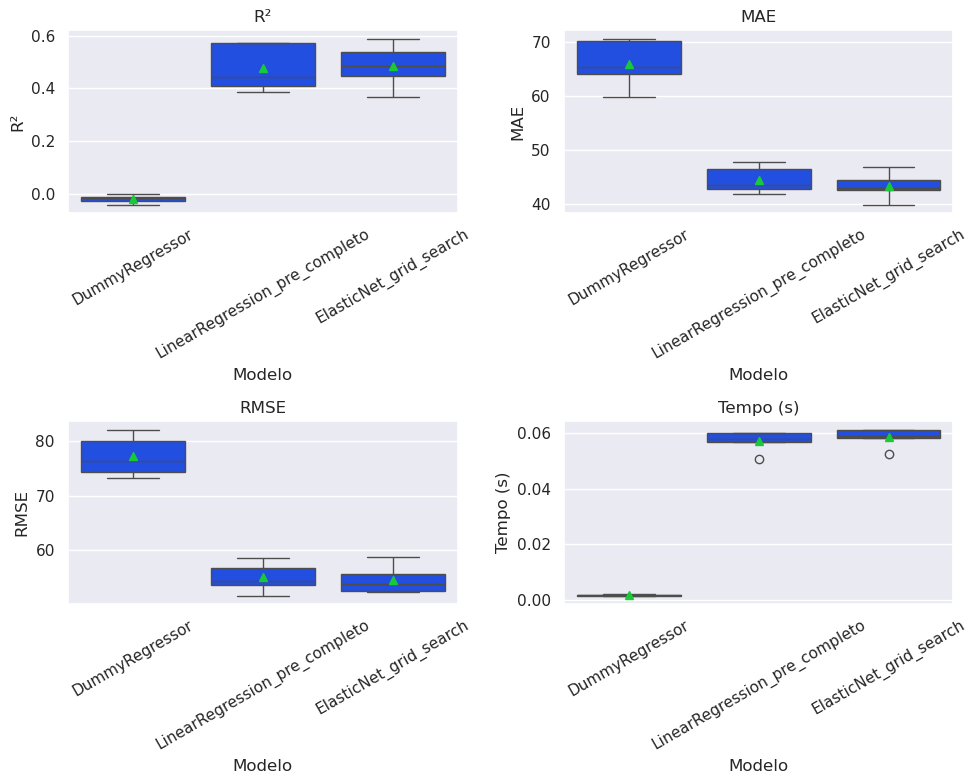

In [30]:
plot_comparar_metricas_modelos(df_resultados)